#Import Library

In [1]:
import pandas as pd

In [2]:
#load Datasets

In [3]:
data = pd.read_csv('heart.csv')

In [4]:
#check Missing Values

In [5]:
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [6]:
#checking Duplicate Values

In [7]:
data_dup = data.duplicated().any() 

In [8]:
data_dup

True

In [9]:
data = data.drop_duplicates()

In [10]:
data_dup = data.duplicated().any() 

In [11]:
data_dup

False

Data Processing

In [12]:
cate_val=[]
cont_val=[]

for column in data.columns:
    if data[column].nunique() <=10:
        cate_val.append(column)
    else:
        cont_val.append(column)

In [13]:
cate_val

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [14]:
cont_val

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

#Encoding Catergorical Data

In [15]:
cate_val

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [16]:
data['cp'].unique()

array([0, 1, 2, 3], dtype=int64)

In [17]:
cate_val.remove('sex')
cate_val.remove('target')
data = pd.get_dummies(data,columns=cate_val,drop_first=True)

In [18]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,168,1.0,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,155,3.1,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,70,1,145,174,125,2.6,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,61,1,148,203,161,0.0,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,106,1.9,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


#Feature Scaling

In [19]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,1,125,212,168,1.0,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,53,1,140,203,155,3.1,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,70,1,145,174,125,2.6,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,61,1,148,203,161,0.0,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,62,0,138,294,106,1.9,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
st = StandardScaler()
data[cont_val] = st.fit_transform(data[cont_val])

In [22]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,-0.267966,1,-0.376556,-0.667728,0.806035,-0.037124,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,-0.157260,1,0.478910,-0.841918,0.237495,1.773958,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,1.724733,1,0.764066,-1.403197,-1.074521,1.342748,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0.728383,1,0.935159,-0.841918,0.499898,-0.899544,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,0.839089,0,0.364848,0.919336,-1.905464,0.739054,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


#Splitting Datset into Traning Set and Test set

In [23]:
X = data.drop('target', axis=1)

In [24]:
y = data['target']


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [27]:
y_test

245    1
349    0
135    0
389    1
66     1
      ..
402    1
123    1
739    0
274    1
256    1
Name: target, Length: 61, dtype: int64

#Logistic Regression

In [28]:
data.head()

,age,sex,trestbps,chol,thalach,oldpeak,target,cp_1,cp_2,cp_3,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,-0.267966,1,-0.376556,-0.667728,0.806035,-0.037124,0,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,-0.157260,1,0.478910,-0.841918,0.237495,1.773958,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
2,1.724733,1,0.764066,-1.403197,-1.074521,1.342748,0,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,0.728383,1,0.935159,-0.841918,0.499898,-0.899544,0,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,0.839089,0,0.364848,0.919336,-1.905464,0.739054,0,False,False,False,...,False,True,False,False,False,True,False,False,True,False


In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
log = LogisticRegression()
log.fit(X_train,y_train)

LogisticRegression()

In [31]:
y_pred1 = log.predict(X_test)

In [32]:
from sklearn.metrics import accuracy_score

In [33]:
accuracy_score(y_test,y_pred1)

0.7868852459016393

#SVC

In [34]:
from sklearn import svm

In [35]:
svm = svm.SVC()

In [36]:
 svm.fit(X_train,y_train)

SVC()

In [37]:
y_pred2 = svm.predict(X_test)

In [38]:
accuracy_score(y_test,y_pred2)

0.8032786885245902

#KNighbors Classfier

In [39]:
from sklearn.neighbors import KNeighborsClassifier

In [40]:
Knn = KNeighborsClassifier()

In [100]:
Knn.fit(X_train,y_train)

KNeighborsClassifier()

In [101]:
y_pred3=Knn.predict(X_test)

In [102]:
accuracy_score(y_test,y_pred3)

0.639344262295082

In [103]:
score = []
for k in range(1,40):
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    score.append(accuracy_score(y_test,y_pred))

In [104]:
score

[0.5737704918032787,
 0.5737704918032787,
 0.639344262295082,
 0.6229508196721312,
 0.639344262295082,
 0.6229508196721312,
 0.6229508196721312,
 0.6721311475409836,
 0.6065573770491803,
 0.5901639344262295,
 0.5737704918032787,
 0.6065573770491803,
 0.5901639344262295,
 0.6065573770491803,
 0.5573770491803278,
 0.5901639344262295,
 0.5737704918032787,
 0.6065573770491803,
 0.6229508196721312,
 0.5901639344262295,
 0.5573770491803278,
 0.5901639344262295,
 0.6065573770491803,
 0.6065573770491803,
 0.6065573770491803,
 0.6065573770491803,
 0.6229508196721312,
 0.6557377049180327,
 0.6065573770491803,
 0.6229508196721312,
 0.6229508196721312,
 0.6065573770491803,
 0.5737704918032787,
 0.6065573770491803,
 0.5737704918032787,
 0.6065573770491803,
 0.5901639344262295,
 0.5901639344262295,
 0.5737704918032787]

In [105]:
knn=KNeighborsClassifier(n_neighbors=2)
knn.fit(X_train,y_train)
y_pred=knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.5737704918032787

In [106]:
#Non Linear ML Algorithims

In [107]:
data = pd.read_csv('heart.csv')

In [108]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [109]:
data = data.drop_duplicates()

In [110]:
data.shape

(302, 14)

In [111]:
X = data.drop('target',axis=1)
y=data['target']

In [112]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [113]:
#Descision Tree Classifier

In [114]:
from sklearn.tree import DecisionTreeClassifier

In [115]:
dt = DecisionTreeClassifier()

In [116]:
dt.fit(X_train,y_train)

DecisionTreeClassifier()

In [117]:
y_pred4= dt.predict(X_test)

In [118]:
accuracy_score(y_test,y_pred4)

0.7213114754098361

In [119]:
#Random Forest Classifier

In [120]:
from sklearn.ensemble import RandomForestClassifier

In [121]:
rf = RandomForestClassifier()

In [122]:
rf.fit(X_train,y_train)

RandomForestClassifier()

In [123]:
y_pred5= rf.predict(X_test)

In [124]:
accuracy_score(y_test,y_pred5)

0.8524590163934426

In [125]:
#Gradient Boosting Classifier

In [126]:
from sklearn.ensemble import GradientBoostingClassifier

In [127]:
gbc = GradientBoostingClassifier()

In [128]:
gbc.fit(X_train,y_train)

GradientBoostingClassifier()

In [129]:
y_pred6= gbc.predict(X_test)

In [130]:
accuracy_score(y_test,y_pred6)

0.819672131147541

In [131]:
final_data = pd.DataFrame({'Models':['LR','SVM','KNN','DT','RF','GB'],
                           'ACC':[accuracy_score(y_test,y_pred1),
                                  accuracy_score(y_test,y_pred2),
                                  accuracy_score(y_test,y_pred3),
                                  accuracy_score(y_test,y_pred4),
                                  accuracy_score(y_test,y_pred5),
                                  accuracy_score(y_test,y_pred6),
                                 ]})

In [132]:
final_data

,Models,ACC
0,LR,0.786885
1,SVM,0.803279
2,KNN,0.639344
3,DT,0.721311
4,RF,0.852459
5,GB,0.819672


In [133]:
import seaborn as sns 

<Axes: xlabel='Models', ylabel='ACC'>

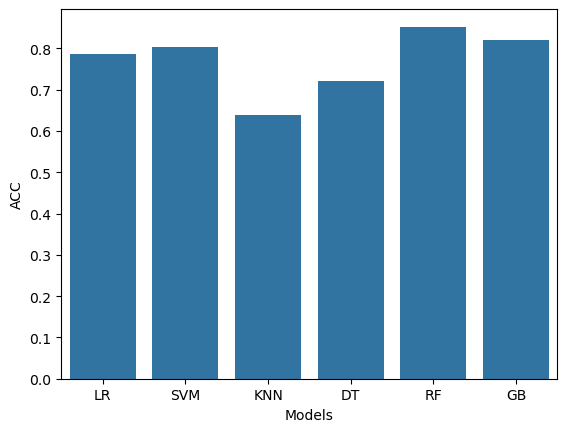

In [134]:
sns.barplot(x=final_data['Models'], y=final_data['ACC'])

In [135]:
X = data.drop('target',axis=1)
y=data['target']

In [136]:
X.shape

(302, 13)

In [137]:
from sklearn.ensemble import RandomForestClassifier

In [138]:
rf = RandomForestClassifier()
rf.fit(X,y)

RandomForestClassifier()

In [88]:
#Save Model using Joblib

In [89]:
import joblib

In [90]:
joblib.dump(rf,'Best_Heart_Diseases_Predict_Model')

['Best_Heart_Diseases_Predict_Model']

In [91]:
#Load_Model

In [92]:
model = joblib.load('Best_Heart_Diseases_Predict_Model')

In [93]:
import pandas as pd
new_data = pd.DataFrame({
    'age':52,
    'sex':1,
    'cp':0,
    'trestbps':125,
    'chol':212,
    'fbs':0,
    'restecg':1,
    'thalach':168,
    'exang':0,
    'oldpeak':1.0,
     'slope':2,
    'ca':2,
    'thal':3,    
},index=[0])


In [94]:
new_data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3


In [96]:
#New_Data

In [95]:
p = rf.predict(new_data)
if p[0]==0:
    print("No Disease")
else:
    print("Disease")

No Disease


In [97]:
#GUI

In [3]:
from tkinter import *
import joblib
from tkinter import *
import joblib
import numpy as np
from sklearn import *

def show_entry_fields():
    p1=int(e1.get())
    p2=int(e2.get())
    p3=int(e3.get())
    p4=int(e4.get())
    p5=int(e5.get())
    p6=int(e6.get())
    p7=int(e7.get())
    p8=int(e8.get())
    p9=int(e9.get())
    p10=float(e10.get())
    p11=int(e11.get())
    p12=int(e12.get())
    p13=int(e13.get())
    model = joblib.load('Best_Heart_Diseases_Predict_Model')
    result=model.predict([[p1,p2,p3,p4,p5,p6,p7,p8,p8,p10,p11,p12,p13]])
    if result == 0:
        Label(master, text="No Heart Disease").grid(row=31)
    else:
        Label(master, text="Possibility of Heart Disease").grid(row=31)
    
    
master = Tk()
master.title("Heart Disease Prediction System")


label = Label(master, text = "Heart Disease Prediction System"
                          , bg = "black", fg = "white"). \
                               grid(row=0,columnspan=2)
Label(master, text="Enter Your Age").grid(row=1)
Label(master, text="Male Or Female [1/0]").grid(row=2)
Label(master, text="Enter Value of CP").grid(row=3)
Label(master, text="Enter Value of trestbps").grid(row=4)
Label(master, text="Enter Value of chol").grid(row=5)
Label(master, text="Enter Value of fbs").grid(row=6)
Label(master, text="Enter Value of restecg").grid(row=7)
Label(master, text="Enter Value of thalach").grid(row=8)
Label(master, text="Enter Value of exang").grid(row=9)
Label(master, text="Enter Value of oldpeak").grid(row=10)
Label(master, text="Enter Value of slope").grid(row=11)
Label(master, text="Enter Value of ca").grid(row=12)
Label(master, text="Enter Value of thal").grid(row=13)



e1 = Entry(master)
e2 = Entry(master)
e3 = Entry(master)
e4 = Entry(master)
e5 = Entry(master)
e6 = Entry(master)
e7 = Entry(master)
e8 = Entry(master)
e9 = Entry(master)
e10 = Entry(master)
e11 = Entry(master)
e12 = Entry(master)
e13 = Entry(master)
e1.grid(row=1, column=1)
e2.grid(row=2, column=1)
e3.grid(row=3, column=1)
e4.grid(row=4, column=1)
e5.grid(row=5, column=1)
e6.grid(row=6, column=1)
e7.grid(row=7, column=1)
e8.grid(row=8, column=1)
e9.grid(row=9, column=1)
e10.grid(row=10, column=1)
e11.grid(row=11, column=1)
e12.grid(row=12, column=1)
e13.grid(row=13, column=1)



Button(master, text='Predict', command=show_entry_fields).grid()

mainloop()
    

In [140]:
pip install joblib scikit-learn pillow fpdf

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for fpdf: filename=fpdf-1.7.2-py2.py3-none-any.whl size=40714 sha256=302592de6dea57018523b0b474d976218648fbc88272dfde96c2b6069536bad6
  Stored in directory: c:\users\administrator\appdata\local\pip\cache\wheels\6e\62\11\dc73d78e40a218ad52e7451f30166e94491be013a7850b5d75
Successfully built fpdf
Note: you may need to restart the kernel to use updated packages.


In [1]:

# ============================================================
#  Heart Disease Prediction System — Beautiful GUI
#  Requires: Best_Heart_Diseases_Predict_Model  (joblib model)
#            in the same folder as this script.
#  Libraries: pip install joblib scikit-learn pillow fpdf
# ============================================================

import os
import tkinter as tk
from tkinter import ttk, messagebox
import tkinter.font as tkfont
from datetime import datetime

import joblib
import numpy as np
from PIL import Image, ImageDraw, ImageTk
from fpdf import FPDF

# ------------------- CONFIG -------------------
MODEL_FILE   = "Best_Heart_Diseases_Predict_Model"
RECEIPT_DIR  = "receipts"
BG_DARK      = "#0d1b2a"
BG_CARD      = "#16263a"
BG_ENTRY     = "#1f3350"
FG_TEXT      = "#e8edf5"
FG_MUTED     = "#9fb0c7"
ACCENT       = "#ff4d6d"
ACCENT_SOFT  = "#ff758f"
GOOD_GREEN   = "#2ec27e"
BAD_RED      = "#e64545"
FONT_MAIN    = "Segoe UI"   # falls back gracefully to Helvetica on other OS

FIELDS = [
    ("Age",                        "int"),
    ("Sex  (1 = Male / 0 = Female)","int"),
    ("CP (chest pain type)",        "int"),
    ("trestbps (resting BP)",       "int"),
    ("chol (cholesterol)",          "int"),
    ("fbs (fasting blood sugar)",   "int"),
    ("restecg",                     "int"),
    ("thalach (max heart rate)",    "int"),
    ("exang (exercise angina)",     "int"),
    ("oldpeak (ST depression)",     "float"),
    ("slope",                       "int"),
    ("ca (major vessels)",          "int"),
    ("thal",                        "int"),
]

# ---------------- HEART IMAGE (drawn at runtime) --------------
def make_heart_image(size=110, color=(255, 77, 109)):
    img = Image.new("RGBA", (size, size), (0, 0, 0, 0))
    d = ImageDraw.Draw(img)
    s = size
    # two circles + downward triangle make a heart
    r = s * 0.30
    cx1, cy = s * 0.35, s * 0.38
    cx2 = s * 0.65
    d.ellipse([cx1 - r, cy - r, cx1 + r, cy + r], fill=color)
    d.ellipse([cx2 - r, cy - r, cx2 + r, cy + r], fill=color)
    d.polygon([(s*0.13, s*0.48), (s*0.87, s*0.48), (s*0.50, s*0.92)], fill=color)
    # ECG line across the heart
    mid = s * 0.50
    d.line([(s*0.10, mid), (s*0.32, mid), (s*0.40, mid - s*0.16),
            (s*0.48, mid + s*0.18), (s*0.56, mid), (s*0.90, mid)],
           fill=(255, 255, 255, 230), width=max(2, s // 28))
    return img

# ------------------------- APP -------------------------------
class HeartApp(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Heart Diseases Prediction System")
        self.configure(bg=BG_DARK)
        self.geometry("1100x760")
        self.minsize(1020, 700)
        self.resizable(True, True)

        # root grid: column 0 = form (flexible), column 1 = radar side panel
        self.grid_columnconfigure(0, weight=1)
        self.grid_columnconfigure(1, weight=0, minsize=300)
        self.grid_rowconfigure(1, weight=1)

        # model (load once)
        try:
            self.model = joblib.load(MODEL_FILE)
        except Exception as e:
            messagebox.showerror("Model Error",
                                 f"Could not load '{MODEL_FILE}'.\n{e}")
            self.model = None

        self.style()
        self.build_header()
        self.build_form()
        self.build_radar()
        self.build_actions()
        self.entries[0].focus_set()

    # ---------- styling ----------
    def style(self):
        self.option_add("*Font", (FONT_MAIN, 11))
        s = ttk.Style(self)
        try:
            s.theme_use("clam")
        except tk.TclError:
            pass

    # ---------- header: heart image + title ----------
    def build_header(self):
        header = tk.Frame(self, bg=BG_CARD)
        header.grid(row=0, column=0, columnspan=2, sticky="ew",
                    padx=14, pady=(14, 6))

        self.heart_img = ImageTk.PhotoImage(make_heart_image(96))
        tk.Label(header, image=self.heart_img, bg=BG_CARD).pack(side="left", padx=(18, 10), pady=12)

        right = tk.Frame(header, bg=BG_CARD)
        right.pack(side="left", pady=12)

        tk.Label(right, text="Heart Diseases Prediction System",
                 font=(FONT_MAIN, 22, "bold"), fg=FG_TEXT, bg=BG_CARD).pack(anchor="w")
        tk.Label(right, text="AI-assisted cardiac risk screening — fill the patient details below",
                 font=(FONT_MAIN, 11), fg=FG_MUTED, bg=BG_CARD).pack(anchor="w")

    # ---------- patient name + 13 fields ----------
    def build_form(self):
        wrap = tk.Frame(self, bg=BG_DARK)
        wrap.grid(row=1, column=0, sticky="nsew", padx=(14, 4), pady=6)

        # patient name row
        name_card = tk.Frame(wrap, bg=BG_CARD, highlightbackground=ACCENT,
                             highlightthickness=1)
        name_card.pack(fill="x", pady=(0, 10))
        tk.Label(name_card, text="Patient Name", font=(FONT_MAIN, 12, "bold"),
                 fg=ACCENT_SOFT, bg=BG_CARD).pack(side="left", padx=16, pady=10)
        self.patient_name = tk.Entry(name_card, font=(FONT_MAIN, 12, "bold"),
                                     fg=FG_TEXT, bg=BG_ENTRY, relief="flat",
                                     insertbackground=FG_TEXT, width=40)
        self.patient_name.pack(side="left", padx=8, pady=10, fill="x", expand=True)

        # fields in two columns
        grid = tk.Frame(wrap, bg=BG_DARK)
        grid.pack(fill="x")
        self.entries = []
        half = (len(FIELDS) + 1) // 2
        for col in range(2):
            colf = tk.Frame(grid, bg=BG_DARK)
            colf.pack(side="left", fill="both", expand=True, padx=(0 if col == 0 else 8, 8 if col == 0 else 0))
            for row, (label, kind) in enumerate(FIELDS[col*half:(col+1)*half]):
                cell = tk.Frame(colf, bg=BG_CARD)
                cell.pack(fill="x", pady=4)
                tk.Label(cell, text=label, font=(FONT_MAIN, 10), fg=FG_MUTED,
                         bg=BG_CARD, width=26, anchor="w").pack(side="left", padx=(12, 4), pady=7)
                e = tk.Entry(cell, font=(FONT_MAIN, 11), fg=FG_TEXT, bg=BG_ENTRY,
                             relief="flat", insertbackground=FG_TEXT, width=14,
                             justify="center")
                e.pack(side="right", padx=12, pady=7, ipady=2)
                e._kind = kind
                self.entries.append(e)

    # ---------- radar / progress area (side panel, never overlaps the form) ----------
    def build_radar(self):
        panel = tk.Frame(self, bg=BG_CARD, highlightbackground="#274060",
                         highlightthickness=1, width=280)
        panel.grid(row=1, column=1, sticky="nsew", padx=(4, 14), pady=6)
        panel.grid_propagate(False)

        tk.Label(panel, text="SCAN MONITOR", font=(FONT_MAIN, 12, "bold"),
                 fg=FG_MUTED, bg=BG_CARD).pack(pady=(18, 6))

        self.radar_canvas = tk.Canvas(panel, width=170, height=170,
                                      bg=BG_CARD, highlightthickness=0)
        self.radar_canvas.pack(pady=6)

        self.radar_label = tk.Label(panel, text="Ready to scan", font=(FONT_MAIN, 12, "bold"),
                                    fg=ACCENT_SOFT, bg=BG_CARD)
        self.radar_label.pack(pady=(8, 4))

        self.result_label = tk.Label(panel, text="", font=(FONT_MAIN, 13, "bold"),
                                     bg=BG_CARD, wraplength=250, justify="center")
        self.result_label.pack(pady=(6, 10), padx=10, fill="x")

        tk.Label(panel, text="Radar sweep = prediction in progress",
                 font=(FONT_MAIN, 8), fg=FG_MUTED, bg=BG_CARD).pack(side="bottom", pady=10)
        self._angle = 0
        self._sweep_id = None

    def draw_radar(self):
        c = self.radar_canvas
        c.delete("all")
        cx = cy = 85
        # concentric rings
        for r in (80, 60, 40, 20):
            c.create_oval(cx-r, cy-r, cx+r, cy+r, outline="#2e4a6b", width=1)
        # cross hairs
        c.create_line(cx-80, cy, cx+80, cy, fill="#243b57")
        c.create_line(cx, cy-80, cx, cy+80, fill="#243b57")
        # sweeping radar wedge
        a = self._angle
        x1 = cx + 78 * np.cos(np.radians(a))
        y1 = cy + 78 * np.sin(np.radians(a))
        x2 = cx + 78 * np.cos(np.radians(a + 40))
        y2 = cy + 78 * np.sin(np.radians(a + 40))
        c.create_polygon(cx, cy, x1, y1, x2, y2,
                         fill=ACCENT, stipple="gray50", outline=ACCENT)
        c.create_line(cx, cy, x1, y1, fill=ACCENT_SOFT, width=2)
        c.create_oval(cx-4, cy-4, cx+4, cy+4, fill=ACCENT)
        self._angle = (a + 6) % 360

    # ---------- predict button + receipt button ----------
    def build_actions(self):
        bar = tk.Frame(self, bg=BG_DARK)
        bar.grid(row=2, column=0, columnspan=2, sticky="ew", padx=14, pady=(4, 14))

        self.predict_btn = tk.Button(
            bar, text="  PREDICT  ", font=(FONT_MAIN, 13, "bold"),
            fg="white", bg=ACCENT, activebackground=ACCENT_SOFT,
            relief="flat", cursor="hand2", command=self.start_prediction)
        self.predict_btn.pack(side="left", padx=(4, 10), ipady=6, ipadx=14)

        self.receipt_btn = tk.Button(
            bar, text="  PRINT RECEIPT (PDF)  ", font=(FONT_MAIN, 12, "bold"),
            fg=BG_DARK, bg="#ffd166", activebackground="#ffe08a",
            relief="flat", cursor="hand2", state="disabled",
            command=self.print_receipt)
        self.receipt_btn.pack(side="left", ipady=6, ipadx=10)

        tk.Label(bar, text="Model: Best_Heart_Diseases_Predict_Model",
                 font=(FONT_MAIN, 9), fg=FG_MUTED, bg=BG_DARK).pack(side="right")

    # ---------------- prediction flow ----------------
    def read_inputs(self):
        values = []
        for e, (label, kind) in zip(self.entries, FIELDS):
            raw = e.get().strip()
            if raw == "":
                raise ValueError(f"'{label.split('(')[0].strip()}' is empty.")
            try:
                v = float(raw) if kind == "float" else int(float(raw))
            except ValueError:
                raise ValueError(f"'{label.split('(')[0].strip()}' must be a number.")
            values.append(v)
        return values

    def start_prediction(self):
        if self.model is None:
            messagebox.showerror("Model Error", "Prediction model is not loaded.")
            return
        name = self.patient_name.get().strip()
        if not name:
            messagebox.showwarning("Patient Name", "Please enter the patient name.")
            return
        try:
            self.values = self.read_inputs()
        except ValueError as ve:
            messagebox.showwarning("Invalid Input", str(ve))
            return

        self.predict_btn.config(state="disabled")
        self.result_label.config(text="")
        self.receipt_btn.config(state="disabled")
        self.radar_label.config(text="Analyzing… 0 %")
        self._progress = 0
        self._run_radar()

    def _run_radar(self):
        """Animate a radar sweep + rising percentage, then reveal the result."""
        self.draw_radar()
        self._progress += 2
        if self._progress <= 100:
            self.radar_label.config(text=f"Analyzing… {self._progress} %")
            self._sweep_id = self.after(40, self._run_radar)
        else:
            self._finish_prediction()

    def _finish_prediction(self):
        X = np.array(self.values, dtype=float).reshape(1, -1)
        pred = int(self.model.predict(X)[0])
        prob = None
        if hasattr(self.model, "predict_proba"):
            try:
                prob = float(self.model.predict_proba(X)[0][pred]) * 100
            except Exception:
                prob = None

        self.pred = pred
        self.prob = prob
        self.radar_label.config(text="Scan complete ✔")

        if pred == 0:
            self.result_label.config(
                text=f"✔  No Heart Disease detected\n"
                     + (f"Confidence: {prob:.1f} %" if prob is not None else ""),
                fg=GOOD_GREEN)
        else:
            self.result_label.config(
                text=f"⚠  Possibility of Heart Disease\n"
                     + (f"Risk score: {prob:.1f} %" if prob is not None else ""),
                fg=BAD_RED)

        # auto-generate the PDF receipt, then re-enable buttons
        self.generate_pdf()
        self.receipt_btn.config(state="normal")
        self.predict_btn.config(state="normal")

    # ---------------- PDF receipt ----------------
    def generate_pdf(self):
        os.makedirs(RECEIPT_DIR, exist_ok=True)
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        safe_name = "".join(ch if ch.isalnum() or ch in " _-" else "_"
                            for ch in self.patient_name.get().strip())
        path = os.path.join(RECEIPT_DIR, f"receipt_{safe_name}_{stamp}.pdf")

        pdf = FPDF(unit="mm", format=(80, 150))       # small thermal-receipt size
        pdf.add_page()
        pdf.set_auto_page_break(False, 0)

        # header band
        pdf.set_fill_color(13, 27, 42)
        pdf.rect(0, 0, 80, 26, "F")
        pdf.set_y(7)
        pdf.set_x(0)
        pdf.set_text_color(255, 77, 109)
        pdf.set_font("helvetica", "B", 15)
        pdf.cell(80, 6, "HEART CARE", 0, 1, "C")
        pdf.set_text_color(255, 255, 255)
        pdf.set_font("helvetica", "", 9)
        pdf.cell(80, 5, "Heart Diseases Prediction System", 0, 1, "C")

        # patient + date
        pdf.set_y(30)
        pdf.set_x(8)
        pdf.set_text_color(30, 30, 30)
        pdf.set_font("helvetica", "B", 10)
        pdf.cell(40, 5, "Patient: " + self.patient_name.get().strip())
        pdf.set_font("helvetica", "", 9)
        pdf.cell(32, 5, datetime.now().strftime("%d-%m-%Y %H:%M"), 0, 1, "R")
        pdf.line(8, pdf.get_y() + 1, 72, pdf.get_y() + 1)
        pdf.ln(4)

        # measurements
        pdf.set_font("helvetica", "", 8.5)
        for (label, _), v in zip(FIELDS, self.values):
            name = label.split("(")[0].strip()
            pdf.set_x(8)
            pdf.cell(44, 4.6, name)
            pdf.cell(28, 4.6, "%g" % v, 0, 1, "R")
        pdf.ln(2)
        pdf.line(8, pdf.get_y(), 72, pdf.get_y())
        pdf.ln(3)

        # result
        if self.pred == 0:
            pdf.set_text_color(20, 140, 90)
            verdict = "NO HEART DISEASE DETECTED"
        else:
            pdf.set_text_color(200, 40, 40)
            verdict = "POSSIBILITY OF HEART DISEASE"
        pdf.set_font("helvetica", "B", 11)
        pdf.set_x(4)
        pdf.multi_cell(72, 6, verdict, 0, "C")
        if self.prob is not None:
            pdf.set_font("helvetica", "", 10)
            pdf.set_text_color(60, 60, 60)
            tag = "Confidence" if self.pred == 0 else "Risk score"
            pdf.set_x(4)
            pdf.cell(72, 6, "%s: %.1f %%" % (tag, self.prob), 0, 1, "C")
        pdf.ln(4)
        pdf.set_font("helvetica", "I", 8)
        pdf.set_text_color(120, 120, 120)
        pdf.set_x(4)
        pdf.multi_cell(72, 4,
                       "This is an AI-assisted screening result. "
                       "Please consult a qualified cardiologist.", 0, "C")

        pdf.output(path)
        self.pdf_path = path
        messagebox.showinfo("Receipt Generated",
                            "PDF receipt saved to:\n" + os.path.abspath(path))

    def print_receipt(self):
        if getattr(self, "pdf_path", None) and os.path.exists(self.pdf_path):
            try:
                if os.name == "nt":
                    os.startfile(self.pdf_path)
                else:
                    import subprocess
                    subprocess.Popen(["xdg-open", self.pdf_path])
            except Exception:
                messagebox.showinfo("Receipt", self.pdf_path)
        else:
            messagebox.showwarning("Receipt", "No receipt generated yet - run a prediction first.")


if __name__ == "__main__":
    app = HeartApp()
    app.mainloop()

D:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [4]:

# ============================================================
#  Heart Disease Prediction System — Beautiful GUI
#  Requires: Best_Heart_Diseases_Predict_Model  (joblib model)
#            in the same folder as this script.
#  Libraries: pip install joblib scikit-learn pillow fpdf
# ============================================================

import os
import tkinter as tk
from tkinter import ttk, messagebox
import tkinter.font as tkfont
from datetime import datetime

import joblib
import numpy as np
from PIL import Image, ImageDraw, ImageTk
from fpdf import FPDF

try:
    import openpyxl
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.utils import get_column_letter
    EXCEL_OK = True
except ImportError:
    EXCEL_OK = False

# ------------------- CONFIG -------------------
MODEL_FILE   = "Best_Heart_Diseases_Predict_Model"
RECEIPT_DIR  = "receipts"
EXCEL_FILE   = "patient_records.xlsx"
BG_DARK      = "#0d1b2a"
BG_CARD      = "#16263a"
BG_ENTRY     = "#1f3350"
FG_TEXT      = "#e8edf5"
FG_MUTED     = "#9fb0c7"
ACCENT       = "#ff4d6d"
ACCENT_SOFT  = "#ff758f"
GOOD_GREEN   = "#2ec27e"
BAD_RED      = "#e64545"
FONT_MAIN    = "Segoe UI"   # falls back gracefully to Helvetica on other OS

FIELDS = [
    ("Age",                        "int"),
    ("Sex  (1 = Male / 0 = Female)","int"),
    ("CP (chest pain type)",        "int"),
    ("trestbps (resting BP)",       "int"),
    ("chol (cholesterol)",          "int"),
    ("fbs (fasting blood sugar)",   "int"),
    ("restecg",                     "int"),
    ("thalach (max heart rate)",    "int"),
    ("exang (exercise angina)",     "int"),
    ("oldpeak (ST depression)",     "float"),
    ("slope",                       "int"),
    ("ca (major vessels)",          "int"),
    ("thal",                        "int"),
]

# ---------------- HEART IMAGE (drawn at runtime) --------------
def make_heart_image(size=110, color=(255, 77, 109)):
    img = Image.new("RGBA", (size, size), (0, 0, 0, 0))
    d = ImageDraw.Draw(img)
    s = size
    # two circles + downward triangle make a heart
    r = s * 0.30
    cx1, cy = s * 0.35, s * 0.38
    cx2 = s * 0.65
    d.ellipse([cx1 - r, cy - r, cx1 + r, cy + r], fill=color)
    d.ellipse([cx2 - r, cy - r, cx2 + r, cy + r], fill=color)
    d.polygon([(s*0.13, s*0.48), (s*0.87, s*0.48), (s*0.50, s*0.92)], fill=color)
    # ECG line across the heart
    mid = s * 0.50
    d.line([(s*0.10, mid), (s*0.32, mid), (s*0.40, mid - s*0.16),
            (s*0.48, mid + s*0.18), (s*0.56, mid), (s*0.90, mid)],
           fill=(255, 255, 255, 230), width=max(2, s // 28))
    return img

# ------------------------- APP -------------------------------
class HeartApp(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Heart Diseases Prediction System")
        self.configure(bg=BG_DARK)
        self.geometry("1100x760")
        self.minsize(1020, 700)
        self.resizable(True, True)

        # root grid: column 0 = form (flexible), column 1 = radar side panel
        self.grid_columnconfigure(0, weight=1)
        self.grid_columnconfigure(1, weight=0, minsize=300)
        self.grid_rowconfigure(1, weight=1)

        # model (load once)
        try:
            self.model = joblib.load(MODEL_FILE)
        except Exception as e:
            messagebox.showerror("Model Error",
                                 f"Could not load '{MODEL_FILE}'.\n{e}")
            self.model = None

        self.style()
        self.build_header()
        self.build_form()
        self.build_radar()
        self.build_actions()
        self.entries[0].focus_set()

    # ---------- styling ----------
    def style(self):
        self.option_add("*Font", (FONT_MAIN, 11))
        s = ttk.Style(self)
        try:
            s.theme_use("clam")
        except tk.TclError:
            pass

    # ---------- header: heart image + title ----------
    def build_header(self):
        header = tk.Frame(self, bg=BG_CARD)
        header.grid(row=0, column=0, columnspan=2, sticky="ew",
                    padx=14, pady=(14, 6))

        self.heart_img = ImageTk.PhotoImage(make_heart_image(96))
        tk.Label(header, image=self.heart_img, bg=BG_CARD).pack(side="left", padx=(18, 10), pady=12)

        right = tk.Frame(header, bg=BG_CARD)
        right.pack(side="left", pady=12)

        tk.Label(right, text="Heart Diseases Prediction System",
                 font=(FONT_MAIN, 22, "bold"), fg=FG_TEXT, bg=BG_CARD).pack(anchor="w")
        tk.Label(right, text="AI-assisted cardiac risk screening — fill the patient details below",
                 font=(FONT_MAIN, 11), fg=FG_MUTED, bg=BG_CARD).pack(anchor="w")

    # ---------- patient name + 13 fields ----------
    def build_form(self):
        wrap = tk.Frame(self, bg=BG_DARK)
        wrap.grid(row=1, column=0, sticky="nsew", padx=(14, 4), pady=6)

        # patient name row
        name_card = tk.Frame(wrap, bg=BG_CARD, highlightbackground=ACCENT,
                             highlightthickness=1)
        name_card.pack(fill="x", pady=(0, 10))
        tk.Label(name_card, text="Patient Name", font=(FONT_MAIN, 12, "bold"),
                 fg=ACCENT_SOFT, bg=BG_CARD).pack(side="left", padx=16, pady=10)
        self.patient_name = tk.Entry(name_card, font=(FONT_MAIN, 12, "bold"),
                                     fg=FG_TEXT, bg=BG_ENTRY, relief="flat",
                                     insertbackground=FG_TEXT, width=40)
        self.patient_name.pack(side="left", padx=8, pady=10, fill="x", expand=True)

        # fields in two columns
        grid = tk.Frame(wrap, bg=BG_DARK)
        grid.pack(fill="x")
        self.entries = []
        half = (len(FIELDS) + 1) // 2
        for col in range(2):
            colf = tk.Frame(grid, bg=BG_DARK)
            colf.pack(side="left", fill="both", expand=True, padx=(0 if col == 0 else 8, 8 if col == 0 else 0))
            for row, (label, kind) in enumerate(FIELDS[col*half:(col+1)*half]):
                cell = tk.Frame(colf, bg=BG_CARD)
                cell.pack(fill="x", pady=4)
                tk.Label(cell, text=label, font=(FONT_MAIN, 10), fg=FG_MUTED,
                         bg=BG_CARD, width=26, anchor="w").pack(side="left", padx=(12, 4), pady=7)
                e = tk.Entry(cell, font=(FONT_MAIN, 11), fg=FG_TEXT, bg=BG_ENTRY,
                             relief="flat", insertbackground=FG_TEXT, width=14,
                             justify="center")
                e.pack(side="right", padx=12, pady=7, ipady=2)
                e._kind = kind
                self.entries.append(e)

    # ---------- radar / progress area (side panel, never overlaps the form) ----------
    def build_radar(self):
        panel = tk.Frame(self, bg=BG_CARD, highlightbackground="#274060",
                         highlightthickness=1, width=280)
        panel.grid(row=1, column=1, sticky="nsew", padx=(4, 14), pady=6)
        panel.grid_propagate(False)

        tk.Label(panel, text="SCAN MONITOR", font=(FONT_MAIN, 12, "bold"),
                 fg=FG_MUTED, bg=BG_CARD).pack(pady=(18, 6))

        self.radar_canvas = tk.Canvas(panel, width=170, height=170,
                                      bg=BG_CARD, highlightthickness=0)
        self.radar_canvas.pack(pady=6)

        self.radar_label = tk.Label(panel, text="Ready to scan", font=(FONT_MAIN, 12, "bold"),
                                    fg=ACCENT_SOFT, bg=BG_CARD)
        self.radar_label.pack(pady=(8, 4))

        self.result_label = tk.Label(panel, text="", font=(FONT_MAIN, 13, "bold"),
                                     bg=BG_CARD, wraplength=250, justify="center")
        self.result_label.pack(pady=(6, 10), padx=10, fill="x")

        tk.Label(panel, text="Radar sweep = prediction in progress",
                 font=(FONT_MAIN, 8), fg=FG_MUTED, bg=BG_CARD).pack(side="bottom", pady=10)
        self._angle = 0
        self._sweep_id = None

    def draw_radar(self):
        c = self.radar_canvas
        c.delete("all")
        cx = cy = 85
        # concentric rings
        for r in (80, 60, 40, 20):
            c.create_oval(cx-r, cy-r, cx+r, cy+r, outline="#2e4a6b", width=1)
        # cross hairs
        c.create_line(cx-80, cy, cx+80, cy, fill="#243b57")
        c.create_line(cx, cy-80, cx, cy+80, fill="#243b57")
        # sweeping radar wedge
        a = self._angle
        x1 = cx + 78 * np.cos(np.radians(a))
        y1 = cy + 78 * np.sin(np.radians(a))
        x2 = cx + 78 * np.cos(np.radians(a + 40))
        y2 = cy + 78 * np.sin(np.radians(a + 40))
        c.create_polygon(cx, cy, x1, y1, x2, y2,
                         fill=ACCENT, stipple="gray50", outline=ACCENT)
        c.create_line(cx, cy, x1, y1, fill=ACCENT_SOFT, width=2)
        c.create_oval(cx-4, cy-4, cx+4, cy+4, fill=ACCENT)
        self._angle = (a + 6) % 360

    # ---------- predict button + receipt button ----------
    def build_actions(self):
        bar = tk.Frame(self, bg=BG_DARK)
        bar.grid(row=2, column=0, columnspan=2, sticky="ew", padx=14, pady=(4, 14))

        self.predict_btn = tk.Button(
            bar, text="  PREDICT  ", font=(FONT_MAIN, 13, "bold"),
            fg="white", bg=ACCENT, activebackground=ACCENT_SOFT,
            relief="flat", cursor="hand2", command=self.start_prediction)
        self.predict_btn.pack(side="left", padx=(4, 10), ipady=6, ipadx=14)

        self.receipt_btn = tk.Button(
            bar, text="  PRINT RECEIPT (PDF)  ", font=(FONT_MAIN, 12, "bold"),
            fg=BG_DARK, bg="#ffd166", activebackground="#ffe08a",
            relief="flat", cursor="hand2", state="disabled",
            command=self.print_receipt)
        self.receipt_btn.pack(side="left", ipady=6, ipadx=10)

        self.save_btn = tk.Button(
            bar, text="  SAVE RECORD (EXCEL)  ", font=(FONT_MAIN, 12, "bold"),
            fg="white", bg="#3a7bd5", activebackground="#5a97e6",
            relief="flat", cursor="hand2", state="disabled",
            command=lambda: self.save_record(manual=True))
        self.save_btn.pack(side="left", padx=10, ipady=6, ipadx=10)

        self.reset_btn = tk.Button(
            bar, text="  RESET  ", font=(FONT_MAIN, 12, "bold"),
            fg="white", bg="#5c677d", activebackground="#77839c",
            relief="flat", cursor="hand2",
            command=self.reset_form)
        self.reset_btn.pack(side="left", ipady=6, ipadx=14)

        tk.Label(bar, text="Model: Best_Heart_Diseases_Predict_Model",
                 font=(FONT_MAIN, 9), fg=FG_MUTED, bg=BG_DARK).pack(side="right")

    # ---------------- prediction flow ----------------
    def read_inputs(self):
        values = []
        for e, (label, kind) in zip(self.entries, FIELDS):
            raw = e.get().strip()
            if raw == "":
                raise ValueError(f"'{label.split('(')[0].strip()}' is empty.")
            try:
                v = float(raw) if kind == "float" else int(float(raw))
            except ValueError:
                raise ValueError(f"'{label.split('(')[0].strip()}' must be a number.")
            values.append(v)
        return values

    def start_prediction(self):
        if self.model is None:
            messagebox.showerror("Model Error", "Prediction model is not loaded.")
            return
        name = self.patient_name.get().strip()
        if not name:
            messagebox.showwarning("Patient Name", "Please enter the patient name.")
            return
        try:
            self.values = self.read_inputs()
        except ValueError as ve:
            messagebox.showwarning("Invalid Input", str(ve))
            return

        self.predict_btn.config(state="disabled")
        self.result_label.config(text="")
        self.receipt_btn.config(state="disabled")
        self.radar_label.config(text="Analyzing… 0 %")
        self._progress = 0
        self._run_radar()

    def _run_radar(self):
        """Animate a radar sweep + rising percentage, then reveal the result."""
        self.draw_radar()
        self._progress += 2
        if self._progress <= 100:
            self.radar_label.config(text=f"Analyzing… {self._progress} %")
            self._sweep_id = self.after(40, self._run_radar)
        else:
            self._finish_prediction()

    def _finish_prediction(self):
        X = np.array(self.values, dtype=float).reshape(1, -1)
        pred = int(self.model.predict(X)[0])
        prob = None
        if hasattr(self.model, "predict_proba"):
            try:
                prob = float(self.model.predict_proba(X)[0][pred]) * 100
            except Exception:
                prob = None

        self.pred = pred
        self.prob = prob
        self.radar_label.config(text="Scan complete ✔")

        if pred == 0:
            self.result_label.config(
                text=f"✔  No Heart Disease detected\n"
                     + (f"Confidence: {prob:.1f} %" if prob is not None else ""),
                fg=GOOD_GREEN)
        else:
            self.result_label.config(
                text=f"⚠  Possibility of Heart Disease\n"
                     + (f"Risk score: {prob:.1f} %" if prob is not None else ""),
                fg=BAD_RED)

        # auto-generate the PDF receipt, then re-enable buttons
        self.generate_pdf()
        self.receipt_btn.config(state="normal")
        self.save_btn.config(state="normal")
        self.predict_btn.config(state="normal")

        # automatically log every prediction into the Excel sheet
        self.save_record(manual=False)

    # ---------------- reset form ----------------
    def reset_form(self):
        """Clear patient name, all 13 entries, result text and radar state."""
        self.patient_name.delete(0, "end")
        for e in self.entries:
            e.delete(0, "end")
        self.result_label.config(text="")
        self.radar_label.config(text="Ready to scan")
        self.radar_canvas.delete("all")
        self._angle = 0
        # no saved result anymore
        self.values = None
        self.pred = None
        self.prob = None
        self.pdf_path = None
        self.receipt_btn.config(state="disabled")
        self.save_btn.config(state="disabled")
        self.entries[0].focus_set()

    # ---------------- Excel record keeping ----------------
    def save_record(self, manual=False):
        """Append the current prediction to patient_records.xlsx.
        Creates the workbook with a styled header row on the first record."""
        if not EXCEL_OK:
            messagebox.showerror("Excel Error",
                                 "openpyxl is not installed.\nRun: pip install openpyxl")
            return
        if getattr(self, "pred", None) is None or getattr(self, "values", None) is None:
            messagebox.showwarning("No Record",
                                   "Run a prediction first - there is no record to save.")
            return

        header = ["Date", "Time", "Patient Name"] + \
                 [lbl.split("(")[0].strip() for lbl, _ in FIELDS] + \
                 ["Prediction", "Confidence (%)"]

        now = datetime.now()
        verdict = "No Heart Disease" if self.pred == 0 else "Heart Disease Suspected"
        row = [now.strftime("%d-%m-%Y"), now.strftime("%H:%M:%S"),
               self.patient_name.get().strip()] + \
              list(self.values) + [verdict,
               round(self.prob, 1) if self.prob is not None else ""]

        first_record = not os.path.exists(EXCEL_FILE)
        if first_record:
            wb = openpyxl.Workbook()
            ws = wb.active
            ws.title = "Patient Records"
            ws.append(header)
            # styled header row
            for c in range(1, len(header) + 1):
                cell = ws.cell(row=1, column=c)
                cell.font = Font(bold=True, color="FFFFFF")
                cell.fill = PatternFill("solid", fgColor="1F3350")
                cell.alignment = Alignment(horizontal="center")
                ws.column_dimensions[get_column_letter(c)].width = 18
            wb.save(EXCEL_FILE)

        wb = openpyxl.load_workbook(EXCEL_FILE)
        ws = wb["Patient Records"]
        ws.append(row)
        # light red highlight if disease suspected
        if self.pred == 1:
            for c in range(1, len(header) + 1):
                ws.cell(row=ws.max_row, column=c).fill = \
                    PatternFill("solid", fgColor="FFD6D6")
        wb.save(EXCEL_FILE)

        if manual:
            total = ws.max_row - 1
            messagebox.showinfo("Record Saved",
                                f"Record saved to '{EXCEL_FILE}'.\n"
                                f"Total records in sheet: {total}")

    # ---------------- PDF receipt ----------------
    def generate_pdf(self):
        os.makedirs(RECEIPT_DIR, exist_ok=True)
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        safe_name = "".join(ch if ch.isalnum() or ch in " _-" else "_"
                            for ch in self.patient_name.get().strip())
        path = os.path.join(RECEIPT_DIR, f"receipt_{safe_name}_{stamp}.pdf")

        pdf = FPDF(unit="mm", format=(80, 150))       # small thermal-receipt size
        pdf.add_page()
        pdf.set_auto_page_break(False, 0)

        # header band
        pdf.set_fill_color(13, 27, 42)
        pdf.rect(0, 0, 80, 26, "F")
        pdf.set_y(7)
        pdf.set_x(0)
        pdf.set_text_color(255, 77, 109)
        pdf.set_font("helvetica", "B", 15)
        pdf.cell(80, 6, "HEART CARE", 0, 1, "C")
        pdf.set_text_color(255, 255, 255)
        pdf.set_font("helvetica", "", 9)
        pdf.cell(80, 5, "Heart Diseases Prediction System", 0, 1, "C")

        # patient + date
        pdf.set_y(30)
        pdf.set_x(8)
        pdf.set_text_color(30, 30, 30)
        pdf.set_font("helvetica", "B", 10)
        pdf.cell(40, 5, "Patient: " + self.patient_name.get().strip())
        pdf.set_font("helvetica", "", 9)
        pdf.cell(32, 5, datetime.now().strftime("%d-%m-%Y %H:%M"), 0, 1, "R")
        pdf.line(8, pdf.get_y() + 1, 72, pdf.get_y() + 1)
        pdf.ln(4)

        # measurements
        pdf.set_font("helvetica", "", 8.5)
        for (label, _), v in zip(FIELDS, self.values):
            name = label.split("(")[0].strip()
            pdf.set_x(8)
            pdf.cell(44, 4.6, name)
            pdf.cell(28, 4.6, "%g" % v, 0, 1, "R")
        pdf.ln(2)
        pdf.line(8, pdf.get_y(), 72, pdf.get_y())
        pdf.ln(3)

        # result
        if self.pred == 0:
            pdf.set_text_color(20, 140, 90)
            verdict = "NO HEART DISEASE DETECTED"
        else:
            pdf.set_text_color(200, 40, 40)
            verdict = "POSSIBILITY OF HEART DISEASE"
        pdf.set_font("helvetica", "B", 11)
        pdf.set_x(4)
        pdf.multi_cell(72, 6, verdict, 0, "C")
        if self.prob is not None:
            pdf.set_font("helvetica", "", 10)
            pdf.set_text_color(60, 60, 60)
            tag = "Confidence" if self.pred == 0 else "Risk score"
            pdf.set_x(4)
            pdf.cell(72, 6, "%s: %.1f %%" % (tag, self.prob), 0, 1, "C")
        pdf.ln(4)
        pdf.set_font("helvetica", "I", 8)
        pdf.set_text_color(120, 120, 120)
        pdf.set_x(4)
        pdf.multi_cell(72, 4,
                       "This is an AI-assisted screening result. "
                       "Please consult a qualified cardiologist.", 0, "C")

        pdf.output(path)
        self.pdf_path = path
        messagebox.showinfo("Receipt Generated",
                            "PDF receipt saved to:\n" + os.path.abspath(path))

    def print_receipt(self):
        if getattr(self, "pdf_path", None) and os.path.exists(self.pdf_path):
            try:
                if os.name == "nt":
                    os.startfile(self.pdf_path)
                else:
                    import subprocess
                    subprocess.Popen(["xdg-open", self.pdf_path])
            except Exception:
                messagebox.showinfo("Receipt", self.pdf_path)
        else:
            messagebox.showwarning("Receipt", "No receipt generated yet - run a prediction first.")


if __name__ == "__main__":
    app = HeartApp()
    app.mainloop()

D:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
